### **<u> Introduction <u>**

Intuitivement, on pourrait penser que les crises économiques fragilisent notre état de santé (perte de revenus, stress, précarité…). Pourtant, Gerdtham et Ruhm (2006) montrent au contraire, à partir de données sur 23 pays de l'OCDE entre 1960 et 1997, que la mortalité diminue pour la plupart des causes de décès lorsque le chômage augmente. Plusieurs mécanismes peuvent l'expliquer : en période de récession, on conduit moins, on travaille moins, on consomme moins d'alcool et de tabac, et on dispose de plus de temps pour prendre soin de sa santé. Le suicide fait en revanche exception et tend à augmenter avec le chômage.

Notre objectif est de vérifier si ce résultat tient toujours aujourd'hui, en étendant l'étude à la période 1991–2023 et aux 38 pays désormais membres de l'OCDE. Cette période est particulièrement intéressante, car elle est marquée par plusieurs grands chocs économiques (éclatement de la bulle internet, crise des subprimes, crise de la dette de la zone euro, pandémie de Covid-19). Elle permet aussi d'interroger l'affaiblissement de cette relation observé par Ruhm (2015) depuis les années 1990. Pour obtenir des résultats comparables, nous reprenons leur modèle économétrique.

### **<u> Sommaire <u>**

**Problématique : Les récessions sont-elles bonnes pour la santé ?**

**I. Import des données**
1. Données du Global Burden of Disease (GBD)
2. Données de la Banque mondiale
3. Fusion des deux tables

**II. Statistiques descriptives**
1. Données de mortalité (GBD)
    - a. Résumé statistique 
    - b. Graphiques
  
2. Indicateurs de la Banque mondiale
    - a. Résumé statistique 
    - b. Graphiques

**III. Régressions simples, pays par pays**

**IV. Le chômage et la mortalité toutes causes confondues**
1. Relation entre mortalité et chômage, pays par pays
2. Relation entre mortalité et chômage, année par année
3. Évolution du coefficient de régression au fil des années

**V. Le chômage et la mortalité, cause par cause**
1. Corrélations entre chômage et mortalité
2. Régressions selon la spécification de Gerdtham et Ruhm
3. Hétérogénéité entre pays : le cas du suicide

**Conclusion**

### **<u> I. Import des données <u>**

In [52]:
%pip install -r requirements.txt

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wbgapi as wb
import statsmodels.formula.api as smf
from pathlib import Path
from functools import reduce

np.random.seed(123)

from modules.Fonctions import *

Note: you may need to restart the kernel to use updated packages.


In [53]:
### Constantes

metrics = ["Number", "Percent", "Rate"]
colonness_GBD = ["location_id", "location_name", "cause_id", "cause_name", "metric_id", "metric_name", "year", "value","upper_bound", "lower_bound"]
causes_generales = [["All causes", 1, [294]],["Malignant neoplasm", 2, [1012, 459, 489]], ["Major cardiovascular diseases", 3,[491]], ["Liver diseases, cirrhosis", 4, [521]], ["Pneumonia and influenza", 5, [322]], ["Motor vehicle accidents", 6, [689, 688]],["Suicide", 7, [718]], ["Other accidents", 8, [696]], ["Homicide", 9, [724, 945,854]]]
numero_agg = [1012, 459, 489, 689, 688, 724, 945, 854] # numeros des causes aggrégées
numero_non_agg = [294,491,521,322,718,696] # numeros des causes non aggrégées 

countries = ["AUS", "AUT", "BEL", "CAN", "CHL", "COL", "CRI", "CZE", "DNK", "EST", "FIN", "FRA", "DEU", "GRC", "HUN", "ISL", "IRL", "ISR", "ITA",
             "JPN", "KOR", "LVA", "LTU", "LUX", "MEX", "NLD", "NZL", "NOR", "POL", "PRT", "SVK", "SVN", "ESP", "SWE", "CHE", "TUR", "GBR", "USA"]

indicateurs_vers_croissance = {
    "Taux_chômage": "Croissance_taux_chômage",
    "Taux_chômage_F": "Croissance_chômage_F",
    "Taux_chômage_H": "Croissance_chômage_H",
    "PIB/hab_ppa": "Croissance_PIB_hab_ppa",
    "Population": "Croissance_population",
}

code_vers_label = {
    "SL.UEM.TOTL.ZS": "Taux_chômage",
    "SL.UEM.TOTL.FE.ZS": "Taux_chômage_F",
    "SL.UEM.TOTL.MA.ZS": "Taux_chômage_H",
    "NY.GDP.PCAP.PP.KD": "PIB/hab_ppa",    
    "NY.GNP.PCAP.PP.KD": "RNB/hab_ppa",
    "SP.POP.TOTL": "Population",
    "SP.POP.65UP.TO.ZS": "Pourcentage_pop_65plus",
    "SH.XPD.GHED.GD.ZS": "Pourcentage_PIB_dépenses_santé"
}
#Création d'un tableau qui associe les codes pays à leurs noms complets en anglais
noms_pays = pd.DataFrame({
    "economy": countries,

    "location_name": ["Australia", "Austria", "Belgium", "Canada", "Chile", "Colombia", "Costa Rica",
    "Czechia", "Denmark", "Estonia", "Finland", "France", "Germany", "Greece",
    "Hungary", "Iceland", "Ireland", "Israel", "Italy", "Japan", "South Korea",
    "Latvia", "Lithuania", "Luxembourg", "Mexico", "Netherlands", "New Zealand",
    "Norway", "Poland", "Portugal", "Slovakia", "Slovenia", "Spain", "Sweden",
    "Switzerland", "Turkey", "United Kingdom", "United States"]
})

### <u> 1. Données du GBD

Nous utilisons les données de l'étude GBD (<i>Global Burden of Disease</i>), conduite par l'IHME (<i>Institute for Health Metrcis and Evaluation</i>), pour l'étude de la mortalité par causes dans les pays de l'OCDE. Avant de les importer directement, nous réarrangeons ces données dans un fichier excel :
- nous gardons toutes les catégories de causes de mort sauf la mort infantile car c'est pas le même mode de calcul
- nous ne conservons que les pays qui font partie de l'OCDE (38 pays au total), pour correspondre aux données fournies par World Bank 

Metric (metric_id et metric_name) correspondent à la manière de mesurer les causes de mortalités :
- number = nombres de morts
- percent = nombres de morts pour la cause en question/nombre total de mort dans le pays 
- rate : nombre de morts pour 100k habitants sur l'année
Les valeurs sont indiquées dans la colonne <i>value</i> ; la borne inférieure de l'intervalle de confiance à 95% dans la colonne <i>lower_bound</i>, et la borne supérieure dans la colonne <i>upper_bound</i>.

Le dataframe brute est ainsi construit de la manière suivante : 
- pour chaque pays : 3 x 14 x 44 = 1848 lignes
- 3 car il y a 3 métriques différentes 
- 14 car il y a 14 causes différentes
- 44 car l'étude se fait sur 44 années
- soit un total de 3 métriques x 14 causes x 44 années x 38 pays = 70224 lignes

In [54]:
# Url pour accéder au fichier CSV sur sspcloud
url = "https://minio.lab.sspcloud.fr/guigz/donnees_GBD_uniques.csv"

# Lecture directe du CSV
df_GBD = pd.read_csv(url, sep=";", encoding="latin-1", decimal=",")

df_GBD.head()

,population_group,measure,location_id,location_name,sex,age_name,cause_id,cause_name,metric_id,metric_name,year,value,upper_bound,lower_bound
0,All Population,Deaths,71,Australia,Both,All ages,294,All causes,1,Number,1980,108265.029600,108882.768100,107497.458600
1,All Population,Deaths,71,Australia,Both,All ages,491,Cardiovascular diseases,1,Number,1980,53252.643510,54951.178210,50203.750100
2,All Population,Deaths,71,Australia,Both,All ages,521,Cirrhosis and other chronic liver diseases,1,Number,1980,1390.286718,1469.238444,1314.555387
3,All Population,Deaths,71,Australia,Both,All ages,945,Conflict and terrorism,1,Number,1980,3.999771,4.397038,3.641975
4,All Population,Deaths,71,Australia,Both,All ages,724,Interpersonal violence,1,Number,1980,297.285701,330.648576,270.154420


Le code suivant permet d'obtenir le dataframe final du GBD (celui qui sera utilisé pour les études conduites ultérieurement). Deux idées sont mises en avant dans ce code. 
D'une part, il permet de faire corroborer les causes importées du GBD avec celles évoquées dans l'article <i> Deaths rise in good economic times:Evidence from the OECD </i> : ainsi, certaines causes ont été regroupées ensemble, pour ne former qu'une seule cause "générale". 
D'autre part, il permet de faire corroborer les années d'étude du GBD avec celles de l'étude du World Bank : ainsi, nous enlevons les données antérieures à 1991.
De plus, nous décidons de ne conserver que le taux (nombre de morts pour 100 000 habitants) comme métrique.

In [55]:
GBD_numeric=passage_en_numerique(df_GBD)
GBD_transforme = transformations_dataframe_GBD(GBD_numeric, causes_generales, metrics)
GBD_ordre_alphabete= ajout_numero_pays(GBD_transforme, "location_name", "location_id")

GBD_filtre = filtrage_dataframe(GBD_ordre_alphabete, 1991, 3).sort_values(by=["location_id","metric_id", "year", "cause_id"]).reset_index(drop=True)
GBD_final = GBD_filtre.drop(columns=["ecart_type", "var"])
GBD_final.head(9*33+1)

,location_name,cause_id,cause_name,metric_id,metric_name,year,value,upper_bound,lower_bound,location_id
0,Australia,1,All causes,3,Rate,1991,695.823881,700.496223,690.961278,1
1,Australia,2,Malignant neoplasm,3,Rate,1991,9.208670,9.558780,8.858560,1
2,Australia,3,Major cardiovascular diseases,3,Rate,1991,297.692038,309.566399,272.886999,1
3,Australia,4,"Liver diseases, cirrhosis",3,Rate,1991,7.445414,7.824939,7.008532,1
4,Australia,5,Pneumonia and influenza,3,Rate,1991,10.593496,11.203627,9.583196,1
...,...,...,...,...,...,...,...,...,...,...
293,Australia,6,Motor vehicle accidents,3,Rate,2023,10.983947,11.706293,10.261600,1
294,Australia,7,Suicide,3,Rate,2023,12.288987,13.068551,11.599252,1
295,Australia,8,Other accidents,3,Rate,2023,24.905355,27.991055,20.710593,1
296,Australia,9,Homicide,3,Rate,2023,0.953235,1.058731,0.847738,1


Le dataframe final des données du GBD est ainsi construit de la manière suivante : 
- 10 colonnes
- pour chaque pays : 9 x 33 = 297 lignes
- 9 car il n'y a plus que 9 causes différentes
- 33 car l'étude ne se fait plus que sur 33 années
- un total de 9 causes x 33 années x 38 pays = 11286 lignes

Tableau récapitulatif des correspondances entre nom et numéro d'identité des 38 pays 

In [56]:
locations = GBD_final[["location_id", "location_name"]].drop_duplicates()
locations

,location_id,location_name
0,1,Australia
297,2,Austria
594,3,Belgium
891,4,Canada
1188,5,Chile
1485,6,Colombia
1782,7,Costa Rica
2079,8,Czechia
2376,9,Denmark
2673,10,Estonia


Tableau récapitulatif des correspondances entre nom et numéro d'identité des 9 causes

In [57]:
causes = GBD_final[["cause_id", "cause_name"]].drop_duplicates()
causes

,cause_id,cause_name
0,1,All causes
1,2,Malignant neoplasm
2,3,Major cardiovascular diseases
3,4,"Liver diseases, cirrhosis"
4,5,Pneumonia and influenza
5,6,Motor vehicle accidents
6,7,Suicide
7,8,Other accidents
8,9,Homicide


### <u> 2. Données de la World Bank

##### API

Grâce à l'API de la World Bank, nous pouvons télécharger des données démographiques année par année pour les 38 pays de l'OCDE considérés. Les noms et codes des données téléchargées sont résumés dans le dictionnaire code_vers_label dans la cellule de définition des constantes.

In [58]:
cache_path = Path("data_WB/wb_brut.parquet")

if cache_path.exists():
    df_en_long = pd.read_parquet(cache_path)
else:
    cache_path.parent.mkdir(parents=True, exist_ok=True)
    df_en_long = wb.data.DataFrame(
            list(code_vers_label.keys()),
            economy=countries,
            time=range(1991, 2024),
            columns="series",        # met directement les indicateurs en colonnes
            numericTimeKeys=True     # met directement les années en int (1991, 1992...)
        ).reset_index().rename(columns={"time": "year"})
    
    df_en_long.to_parquet(cache_path)

*Mise en forme et rassemblement des données*

Nos tableaux sont modifiés pour transformer les années en une colonne, puis on joint nos tableaux ensemble pour n'obtenir qu'un seul dataframe en joignant sur le couple (pays, année), afin d'obtenir l'ensemble des données pour tous les pays, sur l'ensemble de la période.

Après avoir changé le nom des colonnes pour qu'ils soient plus parlant, nous obtenons finalement un dataframe de 11 colonnes et 33 années * 38 pays = 1254 lignes.

In [59]:
df_final_WB = labelisation_dataframe_WB(df_en_long, noms_pays, "location_name", "location_id", code_vers_label)

df_final_WB.head(2*33+1)

,year,PIB/hab_ppa,RNB/hab_ppa,Pourcentage_PIB_dépenses_santé,Taux_chômage_F,Taux_chômage_H,Taux_chômage,Pourcentage_pop_65plus,Population,location_name,location_id
0,1991,35670.667864,30292.797235,NaN,9.164,9.887,9.586,11.237463,17284036.0,Australia,1
1,1992,35426.284829,30129.075368,NaN,9.935,11.305,10.733,11.413523,17478635.0,Australia,1
2,1993,36533.146828,31003.190328,NaN,10.004,11.509,10.879,11.579359,17634808.0,Australia,1
3,1994,37622.652477,31777.679986,NaN,9.370,9.983,9.724,11.724779,17805468.0,Australia,1
4,1995,38653.336678,32639.871049,NaN,8.111,8.743,8.473,11.846558,18004882.0,Australia,1
...,...,...,...,...,...,...,...,...,...,...,...
62,2020,60276.330770,61260.452136,8.710238,5.015,5.364,5.201,19.169789,8916864.0,Austria,2
63,2021,62968.853877,64007.465832,9.462125,6.403,6.508,6.459,19.462853,8955797.0,Austria,2
64,2022,65694.459150,64044.877873,8.656315,4.797,5.163,4.992,19.789751,9041851.0,Austria,2
65,2023,64536.207631,63324.658902,8.532197,5.025,5.476,5.264,20.164020,9131761.0,Austria,2


### <u> 3. Merging des deux dataframes en un seul, synthétique.

Nous avons maintenant deux datframes. L'un présentant des données de mortalité issues de la base de données GBD de l'IHME et l'autre présentant des données démographiques issues de la base de données de la World Bank.

Ces des dataframes ont été construits dans l'optique de ne pouvoir en devenir qu'un seul. Ils ont en effet en commun les colonnes *location_id* et *year*. Cela nous permet de réaliser un dataframe synthétisant toutes les données collectées que nous nommons *df_final*. 

Celui-ci contient 16 colonnes et 9 causes * 33 années * 38 pays = 11286 lignes.

In [60]:
df_final = pd.merge(GBD_final.drop(columns=["metric_id", "metric_name"]), df_final_WB.drop(columns=["location_name"]), on=["location_id", "year"], how="outer")
df_final = df_final.rename(columns={"value": "taux_mortalite"}) # renommer value en taux_mortalite
df_final = df_final[["location_name","location_id", "year", "cause_id", "cause_name", "taux_mortalite","upper_bound", "lower_bound","PIB/hab_ppa","RNB/hab_ppa", "Taux_chômage", "Taux_chômage_F", "Taux_chômage_H", "Population", "Pourcentage_pop_65plus", "Pourcentage_PIB_dépenses_santé"]] # on ordonne les colonnes
df_final.head(9*33+1)

,location_name,location_id,year,cause_id,cause_name,taux_mortalite,upper_bound,lower_bound,PIB/hab_ppa,RNB/hab_ppa,Taux_chômage,Taux_chômage_F,Taux_chômage_H,Population,Pourcentage_pop_65plus,Pourcentage_PIB_dépenses_santé
0,Australia,1,1991,1,All causes,695.823881,700.496223,690.961278,35670.667864,30292.797235,9.586,9.164,9.887,17284036.0,11.237463,NaN
1,Australia,1,1991,2,Malignant neoplasm,9.208670,9.558780,8.858560,35670.667864,30292.797235,9.586,9.164,9.887,17284036.0,11.237463,NaN
2,Australia,1,1991,3,Major cardiovascular diseases,297.692038,309.566399,272.886999,35670.667864,30292.797235,9.586,9.164,9.887,17284036.0,11.237463,NaN
3,Australia,1,1991,4,"Liver diseases, cirrhosis",7.445414,7.824939,7.008532,35670.667864,30292.797235,9.586,9.164,9.887,17284036.0,11.237463,NaN
4,Australia,1,1991,5,Pneumonia and influenza,10.593496,11.203627,9.583196,35670.667864,30292.797235,9.586,9.164,9.887,17284036.0,11.237463,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
293,Australia,1,2023,6,Motor vehicle accidents,10.983947,11.706293,10.261600,60684.959620,59439.471532,3.668,3.572,3.755,26659922.0,17.384025,7.659638
294,Australia,1,2023,7,Suicide,12.288987,13.068551,11.599252,60684.959620,59439.471532,3.668,3.572,3.755,26659922.0,17.384025,7.659638
295,Australia,1,2023,8,Other accidents,24.905355,27.991055,20.710593,60684.959620,59439.471532,3.668,3.572,3.755,26659922.0,17.384025,7.659638
296,Australia,1,2023,9,Homicide,0.953235,1.058731,0.847738,60684.959620,59439.471532,3.668,3.572,3.755,26659922.0,17.384025,7.659638


### **<u> II. Statistiques descriptives <u>**

Dans cette partie "descriptive", nous présentons en premier lieu les caractéristiques de notre dataframe final. 

Nous nous efforçons par la suite d'illustrer le contenu même de ce dataframe à l'aide de graphes d'évolution de la mortalité ou de caractéristiques démographiques pour différents pays sur la période 1991-2023. 

#### <u> 1. Global Burden Disease ####

##### <u> a. Statistiques numériques

Ce premier paragraphe s'intéresse au résumé statistique du dataframe issu de GBD. Les variables intéressantes sont les  valeurs de <i> taux_mortalite, upper_bound et lower_bound </i> pour la métrique <i> rate </i>, qui compte le nombre de morts sur une année donnée pour 100 000 habitants du pays considéré au début de ladite année. 
On ne se préoccupe pas des autres colonnes, qui permettent l'identification du pays, de l'année ou de la métrique.

Description pour la cause 1, prenant en compte toutes les morts quelque soit leur origine.

In [61]:
variables_interet= ["taux_mortalite", "upper_bound", "lower_bound"]
    
df_final[df_final["cause_id"]==1][variables_interet].describe(include="all")

,taux_mortalite,upper_bound,lower_bound
count,1254.000000,1254.000000,1254.000000
mean,881.544608,889.385783,873.729974
std,251.534005,253.519335,249.638226
min,375.942414,380.727789,371.149540
25%,685.425650,695.278287,676.007500
50%,907.246538,915.324392,900.143726
75%,1019.013789,1026.163866,1012.073244
max,1760.616170,1774.001181,1747.873159


Dans un premier temps, on constate qu'il n'y a aucune valeur manquante : les trois variables présentent autant de valeurs renseignées que de lignes donc toutes les observations sont renseignées.

De plus, pour chaque mesure, on a bien <i> lower_bound</i> < <i> taux_mortalite</i> < <i> upper_bound </i> : il y a donc cohérence des bornes.

Ensuite, la médiane de <i> taux_mortalite</i> (907) est assez proche de la moyenne (881) et l'écart type (252) représente 29% de cette dernière : la majorité des valeurs sont proches de la moyenne, cette dernière est donc représentative. 

Enfin, les intervalles d'incertitude sont très étroits : les estimations sont donc assez précises.

Nous pourrions réitérer ce résumé statistique pour les 8 autres causes mentionnées dans l'article original. Cependant cela n'apporterait que peu d'informations supplémentaires.

Si, par curiosité, le lecteur souhaite voir la description des valeurs obtenues pour d'autres causes, nous l'invitons à remplacer le chiffre 1 par un autre chiffre compris entre 2 et 9 inclus en se référant au *Tableau récapitulatif des correspondances entre nom et numéro d'identité des 9 causes* (dataframe nommé causes implémenté dans la partie I.1.).

##### <u> b. Graphes

Ce second paragraphe illustre les évolutions des taux de mortalité des différentes causes pour un échantillon de 8 pays sélectionnés aléatoirement. Ces pays sont : 

- l'Australie, 
- l'Estonie
- la France, 
- la Finlande,
- le Japon, 
- la Lettonie, 
- la Lituanie et 
- la Corée du Sud. 

De même que pour le paragraphe précédent, le lecteur peut facilement changer la liste des pays étudiés dans les 3 graphiques suivant en modifiant les numéros au sein de la liste (correspondant au location_id des pays). Il peut de même modifier le numéro de la cause de mortalité illustrée (correspondant au cause_id). Ces numéros et leurs correspondances peuvent être retrouvés au chapitre I.1. aux paragraphes *Tableau récapitulatif des correspondances entre nom et numéro d'identité des 38 pays* & *Tableau récapitulatif des correspondances entre nom et numéro d'identité des 9 causes*.


Nous nous sommes intéressés en premier lieu à l'évolution du taux de mortalité toutes causes confondues.

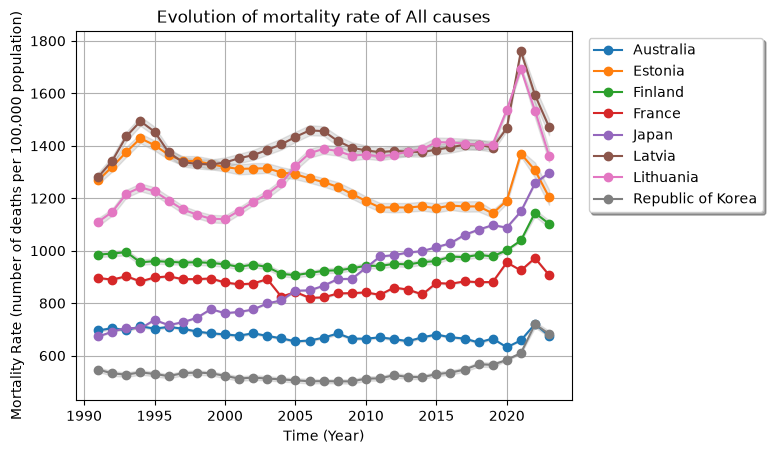

In [62]:
plot_dataframe_multiple_countries_GBD(df_final,1,[1,10,11,12,20,21,22,30]) #All causes

Les intervalles grisés représentent les intervalles de confiance associés à chaque évolution de taux de mortalité pour les pays considérés. 

Tous les pays présentent un pic de mortalité en 2021 et 2022 correspondant à la pandémie de Covid-19.

Ici, les pays semblent se répartir en trois groupes distincts.

Dans un premier temps, les pays baltes (Lettonie, Lituanie, Estonie), qui ont un taux de mortalité (pour 100 000 habitants), toutes causes confondues, supérieur à 1000. L'évolution du taux de mortalité y est fluctuant : un pic en 1994 pour les trois pays, sûrement dû au choc de la transition post-soviétique, et un pic en 2006 pour la Lettonie et la Lituanie.

Dans un second temps, les pays européens et la Corée du Sud, qui ont un taux de mortalité, toutes causes confondues, inférieur à 1000. L'évolution du taux y est stable, voire en baisse, jusqu'aux années 2020. 

Dans un troisième temps, le Japon, dont le taux de mortalité double entre 1991 (environ 700) et 2023 (environ 1300). cela peut être expliqué par le fait que la population japonaise est de plus en plus âgée, et donc exposée à un fort taux de mortalité.

D'autres groupes existent certainement. Nous remarquerons, entre autres, l'absence de pays américains dans ce graphe. 

A présent, nous affinons notre étude, en ne considérant comme cause de mortalité que le suicide.

Cette cause a été mise en avant car d'après l'article de Ruhm de 2006, les taux de mortalité par suicide et homicide augmentent lors de ralentissements économiques, contrairement aux autres taux de mortalité.

In [ ]:
plot_dataframe_multiple_countries_GBD(df_final,7,[1,10,11,12,20,21,22,30]) #Suicide

Il est important de remarquer ici un intervalle de confiance beaucoup plus large que sur le graphe précédent. Il faudra donc interpréter nos résultats avec précautions. 

Globalement, nous voyons des évolutions fortement différentes d'un pays à l'autre, là où l'évolution du taux de mortalité global était plus similaire entre les pays.

On retrouve une tendance pour les pays baltes : le taux de suicide y est plus élevé que dans les autres pays et atteint son pic vers les années 1994/1995 dans les trois pays, encore une fois possiblement expliqué par la transition post-soviétique. Après ce pic, le taux de mortalité diminue continuement, jusqu'à passer en dessous de celui de 1991.

Ensuite, la Finlande et la France suivent une trajectoire décroissante similaire, possiblement expliquée par l'amélioration de la prise en charge psychiatrique dans les pays d'Europe de l'Ouest.

Enfin, le taux de mortalité de la Corée du Sud suit une évolution opposé. En effet, on remarque une augmentation des suicides au cours des années : on passe de 12 suicides pour 100 000 habitants en 1991 à 31 en 2010, avant de stagner, réflètant probablement une différence culturelle importante entre l'Europe et ce pays ou une augmentation de la pression académique et économique.

Nous terminons ces illustrations avec l'évolution du taux de mortalité du aux cancers. 
Cette cause a attiré notre attention de par l'évolution généralement lente des cancers. Le taux de mortalité dû aux cancers une année donnée ne devrait donc pas être corrélée à la situation économique de cette même année, mais plutôt aux situations économiques des années antérieures.

In [ ]:
plot_dataframe_multiple_countries_GBD(df_final,2,[1,10,11,12,20,21,22,30]) #Cancer

On observe une convergence progressive des taux de mortalité des différents pays à partir des années 2000, sûrement provoqué par un vieillissement progressif de la population des pays de l'OCDE.

Néanmoins, avant 2000, les pays baltes et particulièrement la France se démarquent des autres pays avec une évolution en cloche de leur taux de mortalité associé aux cancers avant de retrouver une évolution plus commune. Ce phénomène reste inexpliqué bien que la Seconde Guerre Mondiale ayant eu lieu 50 ans auparavant puisse en être responsable partiellement. 

#### <u> 2. World Bank Indicators ####

##### <u> a. Statistiques numériques

Dans ce troisième paragraphe,nous nous intéressons au résumé statistique du dataframe issu de la World Bank. Les variables intéressantes sont les taux de chômage, les Produit Intérieur Brut et Revenu National Brut par habitant en Parité de Pouvoir d'Achat (PIB et RNB /hab_ppa)
On ne se préoccupe pas des autres colonnes, qui permettent l'identification du pays et de l'année. 

In [ ]:
variables_interet=["Taux_chômage",
    "Taux_chômage_F",
    "Taux_chômage_H",
    "PIB/hab_ppa",
    "RNB/hab_ppa",  
    "Population",
    "Pourcentage_pop_65plus", 
    "Pourcentage_PIB_dépenses_santé"]
    
df_final_WB[variables_interet].describe(include="all")

Grâce au tableau descriptif ci-dessus, nous avons des premières informations sur nos variables d'intérêts, pour tous les pays et années confondues.

Ce tableau permet un premier contrôle pour repérer d'éventuelles valeurs abberantes. Les valeurs (minimum, maximum, moyenne, médiane) semblent cohérentes.

Le chômage féminin semble plus fort que le chômage masculin: la moyenne, les trois quartiles et la valeur maximale sont toutes plus grandes pour les femmes que pour les hommes. NOtre étude portant sur la période 1991-2023, les progrès réalisés ces dernières années en matière d'inégalités de taux d'emploi entre hommes et femmes est sous-estimé par des inégalités plus fortes sur les premières années de de la période. 

En terme de population, la moyenne et la médiane sont très éloignées l'une de l'autre et l'écart type est deux fois plus élevée que la moyenne. Cela suggère une grande hétérogénéité de taille population entre les pays. Ce qui est cohérent avec le fait que des pays allant de l'Islande aux Etats-Unis sont étudiés.

Il en va de même pour la distribution du PIB par habitant bien que notre étude se limite aux pays de l'OCDE.

On remarque également qu'il manque des données :
- de revenu national brut par habitant en parité de pouvoir d'achat ,
- de pourcentage en PIB des dépenses de santé du gouvernement ,


Corrélation entre les variables

In [ ]:
matrice_correlation(df_final, variables_interet, groupe="location_name")

Le tableau de corrélation ci-dessus indique la corrélation entre les différentes variables démographiques retenues moyennées sur la période 1991-2023.
On constate tout d'abord que les indicateurs du chômages sont fortement corrélés positivement, ce qui semble cohérent.
Le PIB/hab est moyennement et négativement corrélé au chômage (-0.48). Il est aussi positivement corrélés aux dépenses de santé(+0.63).

On remarque une très forte corrélation etre PIB et RNB par habitant en PPA (+0.98). Bien que le RNB est considéré par la littérature comme une meilleure mesure du pouvoir d'acaht dans les pays en général, on voit que cette différence est faible au sein des pays de l'OCDE. 
Cette forte corrélation ainsi que l'absence de nombreuses données du RNB nous pousse à retirer le RNB de nos variables explicatives au profit du PIB.

In [ ]:
df_final = df_final.drop(columns="RNB/hab_ppa")

##### <u> b. Graphes

Ce dernier paragraphe illustre la répartition des moyennes par pays et l'évolution des indicateurs démographiques que nous utiliserons pour nos régressions.

In [ ]:
variables = {
    "Taux_chômage": "Taux de chômage (%)",
    "Taux_chômage_F": "Taux de chômage, femmes (%)",
    "Taux_chômage_H": "Taux de chômage, hommes (%)",
    "PIB/hab_ppa": "PIB/hab (PPA, $ constants)",
    "Pourcentage_PIB_dépenses_santé": "Dépenses santé",
    "Population": "Population",
    "Pourcentage_pop_65plus": "Population 65 ans et + (%)",
}

histogrammes_moyennes(df_final_WB, variables)

Les histogrammes ci-dessus décrivent la répartition des 38 pays selon la moyenne de chaque variable sur la période 1991-2023.

Les taux de chômage présentent une distribution asymétrique à droite : la plupart des pays ont un taux moyen compris entre 4 % et 10 %, tandis que quelques pays affichent des niveaux nettement plus élevés, en particulier pour le chômage féminin (jusqu'à environ 20 %). 

Le PIB par habitant est lui aussi asymétrique, avec quelques pays très riches. La population est la variable la plus déséquilibrée : une grande majorité de pays compte moins de 40 millions d'habitants, tandis qu'un pays (les Etats-Unis) dépasse les 300 millions. 

Les dépenses de santé sont réparties de façon plus homogène entre 3 % et 8 % du PIB.

La part de la population plus âgée que 65 ans présente une distribution asymétrique à gauche. La plupart des pays se concentrent entre 12 % et 18 %, avec un regroupement marqué autour de 16-18 % (15 pays sur 38). Un petit groupe de quatre pays se distingue par une proportion de personnes âgées beaucoup plus faible, comprise entre 6 % et 8 %. Cette hétérogénéité reflète des degrés de vieillissement parfois très différents d'un pays à l'autre malgré une forte représentation des pays vieillissants.

In [ ]:
evolutions_moyennes(df_final_WB, variables)

Les graphes ci-dessus représentent l'évolution de la moyenne sur tous les pays des indicateurs démographiques. Ces moyennes ne sont pas pondérées : l'Islande pèse autant que les Etats-Unis dans ces graphes d'évolution. Cette méthode a été retenue pour empêcher d'avoir la dynamique d'un petit groupe de pays très peuplés occultant une dynamique plus globale.


Tout d'abord, les trois courbes de chômage suivent une tendance très semblable : un premier pic entre 1992 et 1998, un second entre 2008 et 2015, et enfin un troisième entre 2019 et 2021.


Le PIB/hab suit une croissance gloabalement linéaire souvent remarquée en théorie macroéconomique. On soulignera tout de même deux interruptions avec une chute du PIB par habitant en 2007 et 2020 (Subprimes et Covid-19).


Les dépenses en santé en pourcentage du PIB (dont les données commencent en 2000) ont une trajectoire en escaliers. Une première hausse au début des années 2000 pour atteindre 5.5%, une seconde hausse en 2006 pour atteindre 6.1% du PIB, et enfin une hausse en 2020 pour atteindre 7% du PIB, mais qui est redescendu à 6.5% du PIB en 2021-2022.


Enfin, la population suit une croissance linéaire. La part de plus de 65 ans dans les pays est en croissance, avec une pente qui augmente à partir de 2010. Alors que les plus de 65 ans représentaient 12% de la population en 1990, ils représentent en 2023 presque 19% de la population, ce qui s'explique par le vieillissement démographiques d'une majorité des pays de l'OCDE.

*Trajectoires des pays*

Afin d'avoir des graphiques observables, on choisit de colorer seulement 6 pays choisis aléatoirement parmi les 38 étudiés. Ceci dans le but d'étudier certaines différences entre ces pays.

- La France, la Corée du Sud et la Lettonie sont en commun avec les graphiques obtenues à partir de GBD.
- L'Allemagne, les Etats-Unis et la Grèce n'y apparaissaient pas.

Les autres pays sont tracés en gris

In [ ]:
evolutions_par_pays(df_final_WB, variables,
    ["France", "Germany", "United States", "Greece", "South Korea", "Latvia"]
)

La Grèce se distingue par la crise de 2008-2015 : le chômage atteint près de 28 % en 2013, plus de 30% chez les femmes et le PIB par habitant recule. 

La Lettonie a aussi subi un chômage élevé sur la période 2008-2013, particulièrement chez les hommes, où il atteint près de 23% au pic tandis qu'il ne dépasse pas 15% chez les femmes durant la même période. Cela est d'autant plus intéressant du fait que lors du pic de 1995, ce taux était très proche entre hommes et femmes.

La Corée du Sud présente un chômage faible et stable mais un vieillissement rapide, la part des 65 ans et plus passant d'environ 5 % en 1991 à plus de 17 % en 2023. Néanmoins ce pourcentage est encore inférieur à la plupart des autres pays de notre étude.

Les États-Unis se caractérisent par une population nettement supérieure aux autres pays et qui continue de croître. La croissance de la population des autres pays est donc "écrasée" par cette valeur extrême. Les Etats-Unis présentent un PIB par habitant élevé ainsi que des dépenses de santé parmi les plus fortes, dépassant la France et l'Allemagne vers 2018. 

Enfin, la France et l'Allemagne suivent des trajectoires proches, avec un chômage plus bas en Allemagne depuis 2008 environ.

Pour les 3 graphiques suivants, nous nous intéressons aux 8 mêmes pays que ceux présentés lors de l'illustration des données de mortalité. 

Nous nous concentrons plus amplement sur : 
- le taux de chômage ;
- le PIB/hab en PPA ; 
- le pourcentage de la population dont l'âge dépasse 65 ans.

In [ ]:
plot_dataframe_multiple_countries_WB(df_final, "Taux_chômage",[1,10,11,12,20,21,22,30]) #Taux de chômage

Les pays européens suivent des tendances similaires en terme de taux de chômage (tous sexes confondus). 

La Corée du Sud voit sont taux de chômage augmenter au début des années 2000 avant de rejoindre une trajectoire similaire à celle des pays européens représentés. 

Pour les pays européens et la Corée du Sud, on remarque deux pics notables : un à la fin des années 90 et un second vers 2010.

D'un autre côté, l'Australie et le Japon ont des trajectoires différentes avec un taux de chômage qui semble plus stable dans le temps, et plus bas que dans les 6 autres pays étudiés ici.

In [ ]:
plot_dataframe_multiple_countries_WB(df_final, "PIB/hab_ppa",[1,10,11,12,20,21,22,30]) #PIB par habitant en PPA

Tous les pays considérés ont une évolution très similaire du PIB par habitant (en parité de pouvoir d'achat) et une trajectoire très proche de l'évolution moyenne présentée précédemment. 

On observe une hausse quasi-linéaire dans le temps, bien que tous les pays subissent une baisse du PIB par habitant en 2007. Il faut remarquer que les pays les plus riches en 1991 voient leur PIB croître moins rapidement que les pays les moins riches cette année.

In [ ]:
plot_dataframe_multiple_countries_WB(df_final, "Pourcentage_pop_65plus",[1,10,11,12,20,21,22,30]) #Pourcentage de la population âgée de 65 ans et plus

Comme vu dans les représentations moyennées discutées  précédemment, l'évolution de la part de la population âgée au sein des pays ont des tendances similaires. On constate ici une augmentation cohérente de la part des plus de 65 ans. 

Ce vieillissement est particulièrement marqué au Japon où la part des plus de 65 ans a plus que doublé entre 1991 et 2023.

### **<u> III. Regressions simples <u>**

Nous consacrons cette section l'étude simple de l'impact du taux de chômage sur la mortalité. Commençons par observer l'évolution du taux de mortalité en fonction du taux de chômage, toutes causes confondues, pour différents pays.

In [ ]:
plot_mortalite_demographie_pays(df_final, "Taux_chômage", 1, [1,10,11,12,20,21,22,30])

On observe un grande hétérogénéité entre les pays. L'Australie et l'Estonie ont un coefficient de régression positif : une augmentation de 1%  du taux de chômage en Australie (resp.Estonie) amène à une augmentation du taux de mortalité de 6 (resp.2) pour 100 000 habitants. Au contraire, la Finlande, la Lithuanie, la Lettonie et la Corée du Sud ont un coefficent de régression négatif.
Deux pays se démarquent :
- la France, dont le coefficient de régression est proche de 0. Le taux de chômage et le taux de mortalité semble être décorrelés.
- le Japon, dont le coefficient de régression (-46) est très négatif comparé aux autres pays. 

Enfin, le R² est très faible pour la plupart des pays (0,00 à 0,12), sauf pour la Corée du Sud (0,42) et l'Australie (0,32). Il semblerait que le taux de chômage ne soit pas la meilleure variable pour prédire le taux de mortalité, toutes causes confondues : les relations trouvées ne sont pas très robustes.

Poursuivons avec l'étude de l'évolution du taux de mortalité, toutes causes confondues, en fonction du PIB par habitants.

In [ ]:
plot_mortalite_demographie_pays(df_final, "PIB/hab_ppa", 1, [1,10,11,12,20,21,22,30])

On remarque dans un premier temps que les R² sont bien plus élevés que pour la régression sur le taux de chômage : le PIB/hab est une variable plus pertinente que le taux de chômage pour prédire le taux de mortalité, toutes causes confondues. De plus, les signes des coefficients de régression sont opposés d'un pays à l'autre. Enfin, la Finlande et la France ont un coefficient de regression nul et un R² très faible : ainsi, pour ces deux pays, le niveau de PIB/habitant n'explique pas le taux de mortalité : la mortalité reste à peu près stable quel que soit le niveau de richesse.

Filtrons maintenant les causes, et ne conservons que le suicide. Commençons par observer l'effet du chômage.

In [ ]:
plot_mortalite_demographie_pays(df_final, "Taux_chômage", 7, [1,10,11,12,20,21,22,30])

0n remarque un coefficent de régression positif pour 7 pays sur 8 : plus le chômage est élevé, plus le taux de suicide est élevé. Par exemple, en France, une augmentation de 1% du taux de chômage amène à une augmentation du taux de suicide de 1,15 pour 100 000 habitants. Les R² sont relativement élevés (sauf pour l'Estonie) : le taux de chômage semble judicieux pour expliquer le taux de suicide dans ces pays. 
La Corée fait exception : son coefficient de régression est négatif (-0,42), mais son R² de 0,07 laisse transparaître que le taux de chômage explique y mal les suicides.

Terminons cette section en étudiant l'évolution du taux de suicides en fonction du PIB par habitant.

In [ ]:
plot_mortalite_demographie_pays(df_final, "PIB/hab_ppa", 7, [1,10,11,12,20,21,22,30])

Tout d'abord, pour tous les pays, le coefficent de la régression du taux de suicide sur le PIB/habitant est du signe opposé de celui de la régression sur le taux de chômage : cela est cohérent. Par exemple, une augmentation de 1% du PIB/habitant en France diminue le taux de suicide de 0,00063 pour 100 000 habitants. La Corée du Sud, tout comme le graphe précédent, suit une trajectoire différente des autres pays. Enfin, les R² sont très élevés comparés aux autres graphes : le PIB/hab est une excellente variable pour prédire le taux de suicide dans la plupart des pays.  

### **<u> IV. Etude de l'impact du chômage sur la mortalité pour toutes causes confondues <u>**

##### <u> 1. On s'intéresse ici au taux de mortalité en fonction du taux de chômage pour chaque pays. <u>

In [ ]:
import importlib
import modules.Econometrics.Etudes_all_causes   
importlib.reload(modules.Econometrics.Etudes_all_causes)
from modules.Econometrics.Etudes_all_causes import *

plot_mortalite_chomage_pays(df_final, ["Australia", "Austria", "Sweden"])

On observe que les régressions différent beaucoup d'un pays à l'autre : le signe ainsi que la valeur du coefficient de regression varie selon les pays. 

##### <u> 2. On s'intéresse ici au taux de mortalité en fonction du taux de chômage pour chaque année. <u>

In [ ]:
plot_mortalite_chomage_annee(df_final, [1996, 2000, 2005,2010, 2015, 2020])

##### <u> 3. On s'intéresse ici à l'évolution du coefficient de la régession de la mortalité sur le chômage au cours des années. <u>

In [ ]:
plot_coeff_reg_mortalite_chomage(df_final)

On observe 4 périodes :
- 1991/1992 : le coefficient est négatif. Une augmentation de 1% du taux de chômage diminue la mortalité de 12 pour 100 000 en 1992 et et de 5 pour 100 000 en 1991.
- 1993 à 2019 : le coefficient est positif (sauf 2007). Trois pics : un en 1995 (+1% du taux de chômage amène à +19 morts pour 100 000 habitants), un en 2005 (+1% du taux de chômage amène à +18 morts pour 100 000 habitants) et le plus grand en 2010 (+1% du taux de chômage amène à +26 morts pour 100 000 habitants).
- 2019 à 2021 (période du covid) : le coefficient redevient négatif
- après 2023 : le coefficient repasse positif, mais n'atteint pas les pics des années 1995, 2005 et 2010


On observe donc globalement une tendance positive : outre lors des grand évènements économiques (exemple du Covid-19), une augmentation du taux de chômage amène à une augmentation de la mortalité, TOUTES CAUSES confondues.

Nous décidons donc de nous intéresser spécifiquement aux différentes causes.

### **<u> V. Etude de l'impact du chômage sur la mortalité, cause par cause <u>**

### a. Etude des corrélations entre taux de chômage et mortalité

*Ici taux de chômage et mortalité et variation taux de chômage (en points) et variation mortalité, pour chaque cause*

In [ ]:
resultat = correlation_par_cause(df_final, "Taux_chômage", "taux_mortalite")
resultat

On calcule, pour chaque cause de décès, la corrélation entre le taux de chômage et le taux de mortalité, en niveaux puis en variations annuelles. En niveaux, les corrélations peuvent être trompeuses (tendances communes, différences entre pays) : par exemple, elles changent de signe pour les accidents de la route.
Deux causes de décès ressortent : le suicide (0,21), qui augmente lorsque le chômage augmente, et les accidents de la route (-0,27), qui baissent quand le chômage augmente. 

### b. Régressions du taux de mortalité sur le taux de chômage

*Régression simple du taux de mortalité sur le taux de chômage pour chacune des causes*

In [ ]:
resultats = pd.DataFrame([regression(df_final, c) for c in df_final["cause_name"].dropna().unique()],
    index=df_final["cause_name"].dropna().unique(),
    columns=["coef", "p-value"]).round(4)

resultats

Suicide : une augmentation de 1 point de pourcentage du chômage est associée à une hausse moyenne d'environ 1,44 % de la mortalité par suicide. L'effet est statistiquement très robuste (p-value<0.01).

Homicide : une augmentation de 1 point de pourcentage du chômage est associée à une hausse moyenne d'environ 1,43 % de la mortalité par suicide. L'effet est statistiquement robuste (p-value<0.05).

*Régression selon le modèle économétrique de Gerdtham et Ruhm*

In [ ]:
resultats = pd.DataFrame( [regression_ruhm(df_final, c) for c in df_final["cause_name"].dropna().unique()],
    index=df_final["cause_name"].dropna().unique(),
    columns=["coef", "p-value"]).round(4)

resultats

En estimant la mortalité selon le taux de chômage de la même manière que Gerdtham et Ruhm (effets fixes pays et année, tendances linéaires par pays, pondération par la racine de la population), nous retrouvons une mortalité globalement procyclique. 

En effet, une hausse d'un point du chômage est associée à une baisse de 0,45 % de la mortalité cardiovasculaire, de 0,96 % de la mortalité routière et de 0,85 % des autres accidents (p < 0,01). 

Le suicide fait exception : il augmente de 1,0 % par point de chômage (p < 0,01). 

L'effet sur la mortalité toutes causes est négatif (−0,16 %) mais non significatif au seuil de 10%. 
Les cancers, les maladies du foie, la pneumonie et l'homicide ne présentent pas de relation significative. Cela peut s'expliquer par le caractère de ces pathologies qui sont longues, et pour lesquelles un choc économique n'affecterait la mortalité qu'avec un décalage de plusieurs années. Notre modèle, ne reliant le taux de chômage et la mortalité de la même année ne permettrait pas d'observer l'effet pour ces maladies.

### c. Hétérogénéité selon les pays : le cas du suicide

In [ ]:
graphe_ruhm(df_final, "Suicide", [1, 10, 11, 12, 20, 21, 22, 30])

Le graphique représente pour les pays considérés, la relation entre chômage et suicide pour chaque pays, une fois neutralisés les effets de la part des 65 ans et plus. La droite en pointillés noirs correspond au coefficient estimé sur l'ensemble des 38 pays de l'OCDE selon la spécification de Ruhm : une hausse d'un point du chômage par rapport à sa tendance est associée à une hausse d'environ 1 % de la mortalité par suicide (p = 0,005).

Cet effet moyen masque toutefois une forte hétérogénéité. La relation est positive dans la plupart des pays : de l'ordre de +2 % par point de chômage dans les pays baltes et en Australie, et plus marquée en Corée du Sud (+4 %) et surtout au Japon (+12 %). Pour ces deux derniers pays, la pente repose sur de faibles variations du chômage.

À l'inverse, la relation est quasiment plate en France (−0,5 %) et en Finlande (−0,3 %). Une explication possible tient au niveau de protection sociale : une assurance chômage plus généreuse et un meilleur accès aux soins pourraient atténuer les conséquences du chômage sur la santé mentale.

### **<u> Conclusion <u>**

Notre étude confirme en partie les résultats de Gerdtham et Ruhm. Sur la période 1991–2023 et pour les 38 pays de l'OCDE, la mortalité diminue lorsque le chômage augmente pour plusieurs causes de décès : une hausse d'un point du chômage est associée à une baisse de 0,45 % de la mortalité cardiovasculaire, de 0,96 % de la mortalité routière et de 0,85 % des autres accidents. Comme dans leur article, le suicide fait exception : il augmente d'environ 1 % par point de chômage. Cet effet varie toutefois fortement d'un pays à l'autre : il est quasi nul en France et en Finlande, et nettement plus marqué dans les pays baltes, en Corée du Sud et au Japon, ce qui pourrait refléter des différences de protection sociale.

En revanche, contrairement à Gerdtham et Ruhm, nous ne trouvons pas d'effet significatif sur la mortalité toutes causes confondues. Les récessions semblent donc toujours réduire certains risques, comme les accidents de la route et les maladies cardiovasculaires, mais elles ne sont plus clairement « bonnes pour la santé » dans leur ensemble.

Notre étude présente plusieurs limites. Nos résultats décrivent des associations et non des effets causaux. Notre modèle relie le chômage et la mortalité d'une même année, et ne capte donc pas les effets différés, probables pour les maladies comme les cancers ou les maladies du foie. 
Pour prolonger ce travail, il serait intéressant d'introduire un chômage retardé de plusieurs années, ou de restreindre l'échantillon aux 23 pays de l'article original afin de mesurer ce qui relève du changement de période et ce qui relève du changement de pays.